# 01 · Exploração do WESAD (sinais de pulso)

**Cronograma:** dia 5 (replanejado para 15/11/2026)

**Objetivo:** entender o WESAD antes de pré-processar. As perguntas são:

1. Como os arquivos estão organizados e quais sinais a pulseira (Empatica E4) registra?
2. Quem são os participantes e quanto tempo dura cada condição do protocolo?
3. Os sinais de pulso mudam de forma visível entre repouso e estresse? Em quais sinais a diferença é mais consistente entre as pessoas?
4. Quantas janelas de 60 s teremos para treinar, e qual o equilíbrio entre as classes?
5. Quais sinais da pulseira de pesquisa podem ser medidos por sensores de baixo custo (experimento central do plano C)?

Usamos só os sinais **do pulso**, porque é o que uma pulseira escolar teria. Os sinais do peito (RespiBAN) ficam de fora.

In [1]:
import sys, pickle
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import neurokit2 as nk

from src.data.wesad import (SUBJECTS, WRIST_FS, LABELS, WESAD_DIR,
                            load_wrist, subject_info)

FIG_DIR = ROOT / "results" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
pd.set_option("display.precision", 2)

COND_COLORS = {"baseline": "#4C72B0", "estresse": "#C44E52",
               "diversao": "#DD8452", "meditacao": "#55A868"}

## 1. Estrutura dos arquivos

Cada participante tem uma pasta `SX/` com:

- `SX.pkl`: sinais já sincronizados do peito e do pulso, mais um rótulo por amostra;
- `SX_E4_Data.zip`: os arquivos brutos da pulseira, como exportados pela Empatica;
- `SX_respiban.txt`: os dados brutos do sensor de peito;
- `SX_quest.csv` e `SX_readme.txt`: questionários e dados pessoais.

Abrimos um `.pkl` uma única vez para ver a estrutura. Ele tem cerca de 1 GB, quase todo do sensor de peito a 700 Hz.

In [2]:
with open(WESAD_DIR / "S2" / "S2.pkl", "rb") as f:
    raw = pickle.load(f, encoding="latin1")

print("chaves:", list(raw.keys()))
for local in ("chest", "wrist"):
    for nome, arr in raw["signal"][local].items():
        print(f"{local:5s} {nome:5s} {str(arr.shape):14s}")
print("label", raw["label"].shape, "(700 Hz, sincronizado ao peito)")
del raw

chaves: ['signal', 'label', 'subject']
chest ACC   (4255300, 3)  
chest ECG   (4255300, 1)  
chest EMG   (4255300, 1)  
chest EDA   (4255300, 1)  
chest Temp  (4255300, 1)  
chest Resp  (4255300, 1)  
wrist ACC   (194528, 3)   
wrist BVP   (389056, 1)   
wrist EDA   (24316, 1)    
wrist TEMP  (24316, 1)    
label (4255300,) (700 Hz, sincronizado ao peito)


In [3]:
s2 = load_wrist("S2")   # só o pulso, com tempo e rótulo alinhados (ver src/data/wesad.py)

pd.DataFrame([
    {"sinal": nome, "taxa (Hz)": WRIST_FS[nome], "amostras": len(df),
     "duração (min)": len(df) / WRIST_FS[nome] / 60,
     "unidade": {"BVP": "sem unidade (fotopletismografia)", "EDA": "µS",
                 "TEMP": "°C", "ACC": "g (3 eixos)"}[nome]}
    for nome, df in s2.items()
])

,sinal,taxa (Hz),amostras,duração (min),unidade
0,BVP,64,389056,101.32,sem unidade (fotopletismografia)
1,EDA,4,24316,101.32,µS
2,TEMP,4,24316,101.32,°C
3,ACC,32,194528,101.32,g (3 eixos)


Os quatro sinais do pulso cobrem exatamente o mesmo período, mas cada um tem sua própria taxa de amostragem: BVP 64 Hz, ACC 32 Hz, EDA e TEMP 4 Hz. O rótulo vem a 700 Hz. Por isso `load_wrist` pega, para cada amostra do pulso, o rótulo do mesmo instante. A aceleração é convertida de 1/64 g para g, e calculamos a magnitude dos três eixos (`mag`).

## 2. Participantes

In [4]:
info = pd.DataFrame([subject_info(s) for s in SUBJECTS]).set_index("subject")
info[["idade", "genero", "mao_dominante"]].T

subject,S2,S3,S4,S5,S6,S7,S8,S9,S10,S11,S13,S14,S15,S16,S17
idade,27,27,25,35,27,28,27,26,28,26,28,27,28,24,29
genero,male,male,male,male,male,male,female,male,male,female,male,male,male,male,female
mao_dominante,right,right,right,right,right,right,left,right,right,right,right,right,right,right,right


In [5]:
print(f"{len(info)} participantes | idade {info.idade.mean():.1f} ± {info.idade.std():.1f} anos "
      f"(mín. {info.idade.min()}, máx. {info.idade.max()})")
print(info.genero.value_counts().to_string())
print()
for s, obs in info.observacoes.dropna().items():
    print(f"{s}: {obs}")

15 participantes | idade 27.5 ± 2.4 anos (mín. 24, máx. 35)
genero
male      12
female     3

S2: The RespiBAN temperature sensor was not fully attached throughout the entire duration of the study protocol.
S3: During the baseline condition, the subject was sitting in a sunny workplace.
Subject provided a valence label of 7 after the stress condition, claiming that he was looking forward to the next condition and was therefore cheerful.
S4: -
S5: Subject might have fallen asleep during the first meditation.
S6: Subject claimed that he had a stressfull week and hence the study was rather relaxing for him.
Stress condition / TSST interview part: subject was not really stressed as he encountered many interviews in the weeks before.
S7: -
S8: Subject had already a rather stressful day, prior to the study.
Subject felt rather cold in the room where the stress condition was carried out.
S9: -
S10: -
S11: -
S13: -
S14: -
S15: Subject didn't really believe the cover story of the stress conditi

O público do WESAD é muito diferente do público-alvo do projeto: são adultos jovens, quase todos homens, estudantes de pós-graduação, sem diagnóstico de TEA. Essa diferença é uma limitação a registrar no relatório. Uma validação em outro público (parte `NURSE` do wearable-and-stress) foi considerada e descartada, porque os rótulos desse dataset não são confiáveis (ver `data/README.md`).

## 3. Rótulos e protocolo

Rótulos do WESAD: 0 = transição, 1 = baseline, 2 = estresse (Trier Social Stress Test: falar em público e fazer contas de cabeça diante de avaliadores), 3 = diversão (vídeos engraçados), 4 = meditação. Os rótulos 5, 6 e 7 devem ser ignorados, segundo o readme oficial.

In [6]:
def segmentos(df: pd.DataFrame, fs: int) -> pd.DataFrame:
    """Trechos contínuos com o mesmo rótulo: início, fim e duração em minutos."""
    lab = df["label"].to_numpy()
    quebras = np.flatnonzero(np.diff(lab)) + 1
    ini = np.r_[0, quebras]
    fim = np.r_[quebras, len(lab)]
    seg = pd.DataFrame({"label": lab[ini], "ini_s": ini / fs, "fim_s": fim / fs})
    seg["dur_min"] = (seg.fim_s - seg.ini_s) / 60
    seg["condicao"] = seg.label.map(LABELS)
    return seg

seg_s2 = segmentos(s2["TEMP"], WRIST_FS["TEMP"])
seg_s2[seg_s2.condicao.notna()].reset_index(drop=True)

,label,ini_s,fim_s,dur_min,condicao
0,1,306.75,1450.75,19.07,baseline
1,2,2273.75,2888.75,10.25,estresse
2,4,4097.75,4488.75,6.52,meditacao
3,3,4763.75,5125.75,6.03,diversao
4,4,5496.75,5873.75,6.28,meditacao


In [7]:
dur = []
for s in SUBJECTS:
    temp = load_wrist(s)["TEMP"]
    cont = temp.label.map(LABELS).value_counts() / WRIST_FS["TEMP"] / 60
    dur.append(cont.rename(s))
dur = pd.DataFrame(dur)[list(LABELS.values())]
dur.loc["média"] = dur.mean()
dur.round(1)

label,baseline,estresse,diversao,meditacao
S2,19.1,10.2,6.0,12.8
S3,19.0,10.7,6.2,13.0
S4,19.3,10.6,6.2,13.4
S5,20.0,10.8,6.2,13.2
S6,19.7,10.8,6.2,13.1
S7,19.8,10.7,6.2,13.2
S8,19.5,11.2,6.2,13.3
S9,19.7,10.8,6.2,13.2
S10,19.7,12.1,6.2,13.3
S11,19.7,11.3,6.1,13.2


Em média, cada participante passa cerca de 20 min em baseline, 11 min em estresse, 6 min em diversão e 13 min em meditação (duas sessões de cerca de 6,5 min). **A classe estresse vai ser minoritária.** A ordem do protocolo muda entre as pessoas. Em 7 participantes (S2, S3, S6, S9, S11, S14, S16) a ordem é baseline → estresse → meditação → diversão → meditação. Nos outros 8, ela é baseline → diversão → meditação → estresse → meditação. Isso ajuda a separar o efeito do estresse do efeito do tempo de sessão.

## 4. Os sinais de um participante ao longo do protocolo

Para ver a sessão inteira, calculamos uma frequência cardíaca (FC) a partir do BVP. O processo detecta os picos de pulso com o `neurokit2`, calcula o intervalo entre batimentos e converte esse intervalo em batimentos por minuto. Intervalos fora de 40 a 180 bpm são descartados como ruído, porque o pulso se mexe e o sensor óptico erra.

In [8]:
FC_MIN, FC_MAX = 40, 180

def fc_do_bvp(bvp: pd.DataFrame, fs: int = WRIST_FS["BVP"]) -> pd.DataFrame:
    """Frequência cardíaca instantânea (bpm) a partir dos picos do BVP."""
    limpo = nk.ppg_clean(bvp["bvp"].to_numpy(), sampling_rate=fs)
    picos = nk.ppg_findpeaks(limpo, sampling_rate=fs)["PPG_Peaks"]
    ibi = np.diff(picos) / fs
    fc = pd.DataFrame({"t": picos[1:] / fs, "fc": 60 / ibi,
                       "label": bvp["label"].to_numpy()[picos[1:]]})
    fc["valido"] = fc.fc.between(FC_MIN, FC_MAX)
    return fc

fc_s2 = fc_do_bvp(s2["BVP"])
print(f"S2: {len(fc_s2)} batimentos detectados, {100 * (~fc_s2.valido).mean():.1f}% descartados como ruído")

S2: 6898 batimentos detectados, 4.4% descartados como ruído


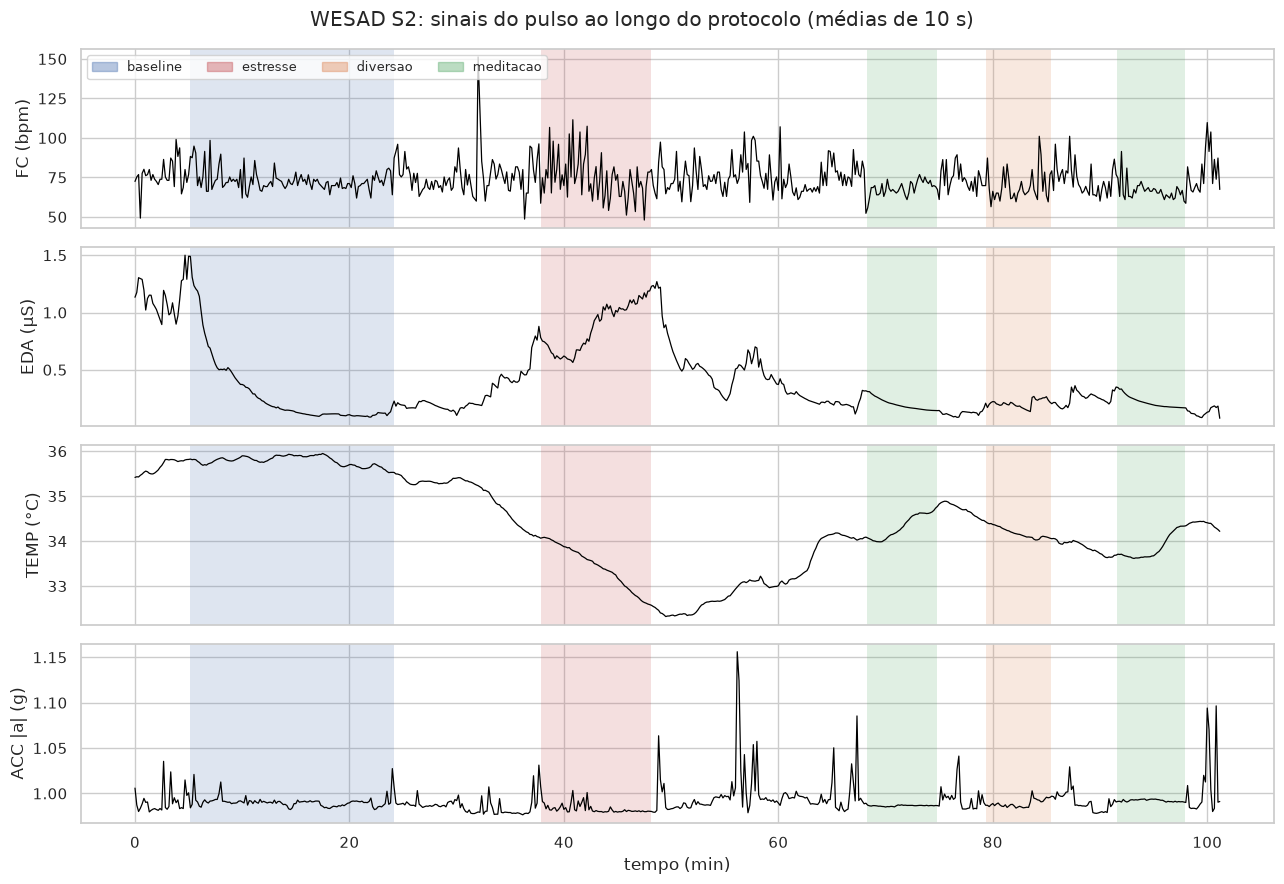

In [9]:
def plot_sessao(sub: str, salvar: bool = False):
    d = load_wrist(sub)
    fc = fc_do_bvp(d["BVP"])
    fc = fc[fc.valido]
    seg = segmentos(d["TEMP"], WRIST_FS["TEMP"])
    seg = seg[seg.condicao.notna()]

    # médias de 10 s para leitura
    def media(df, col, fs):
        return df.groupby((df.t // 10) * 10)[col].mean()

    series = [
        ("FC (bpm)", fc.groupby((fc.t // 10) * 10).fc.median()),
        ("EDA (µS)", media(d["EDA"], "eda", 4)),
        ("TEMP (°C)", media(d["TEMP"], "temp", 4)),
        ("ACC |a| (g)", media(d["ACC"], "mag", 32)),
    ]
    fig, axes = plt.subplots(4, 1, figsize=(13, 9), sharex=True)
    for ax, (nome, s) in zip(axes, series):
        ax.plot(s.index / 60, s.values, color="black", lw=0.9)
        ax.set_ylabel(nome)
        for _, r in seg.iterrows():
            ax.axvspan(r.ini_s / 60, r.fim_s / 60, color=COND_COLORS[r.condicao], alpha=0.18, lw=0)
    handles = [plt.Rectangle((0, 0), 1, 1, color=c, alpha=0.4) for c in COND_COLORS.values()]
    axes[0].legend(handles, COND_COLORS.keys(), ncol=4, loc="upper left", fontsize=9)
    axes[-1].set_xlabel("tempo (min)")
    fig.suptitle(f"WESAD {sub}: sinais do pulso ao longo do protocolo (médias de 10 s)")
    fig.tight_layout()
    if salvar:
        fig.savefig(FIG_DIR / f"01_sessao_{sub}.png", dpi=150)
    plt.show()

plot_sessao("S2", salvar=True)

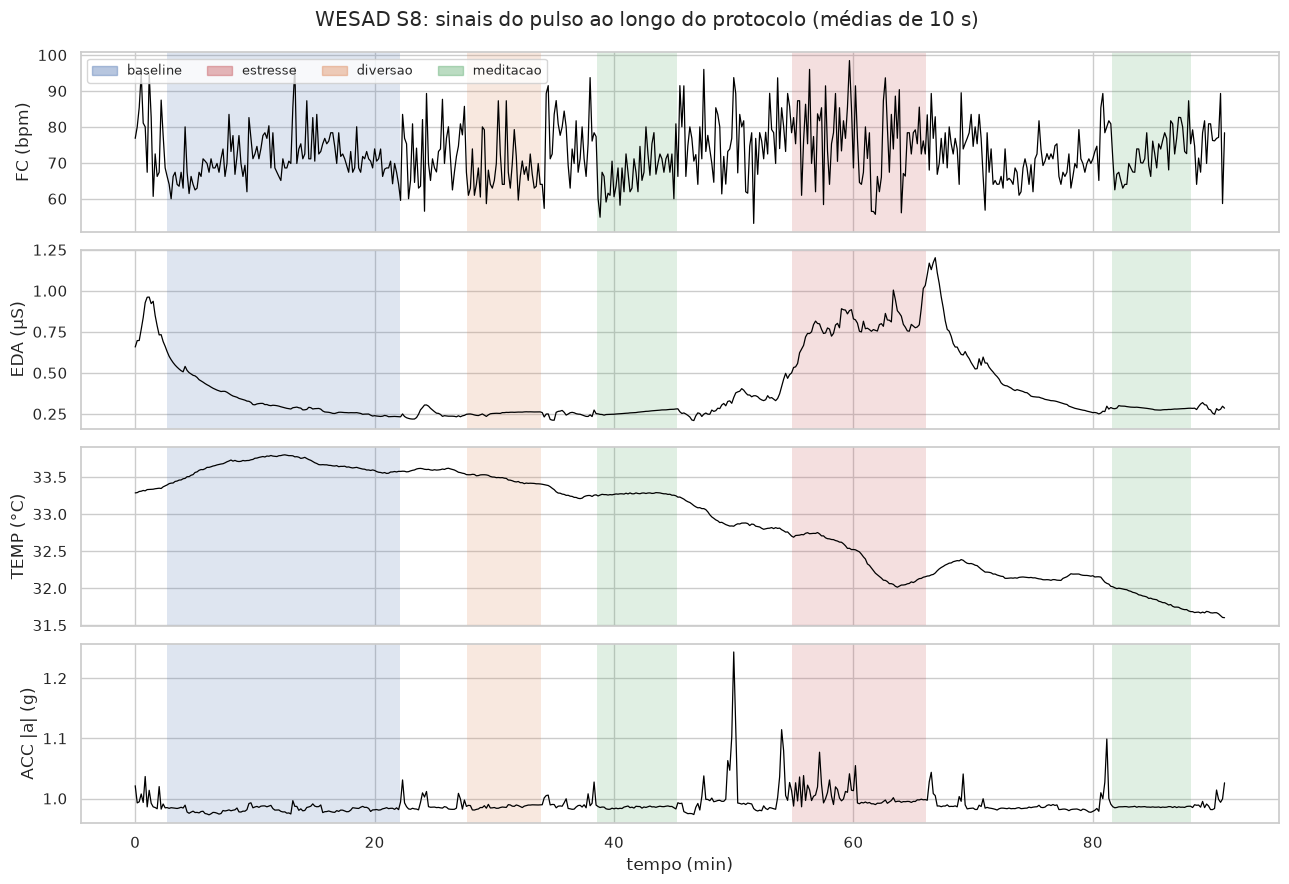

In [10]:
plot_sessao("S8", salvar=True)   # uma participante com protocolo na outra ordem

### Zoom: 10 s de BVP em baseline e em estresse

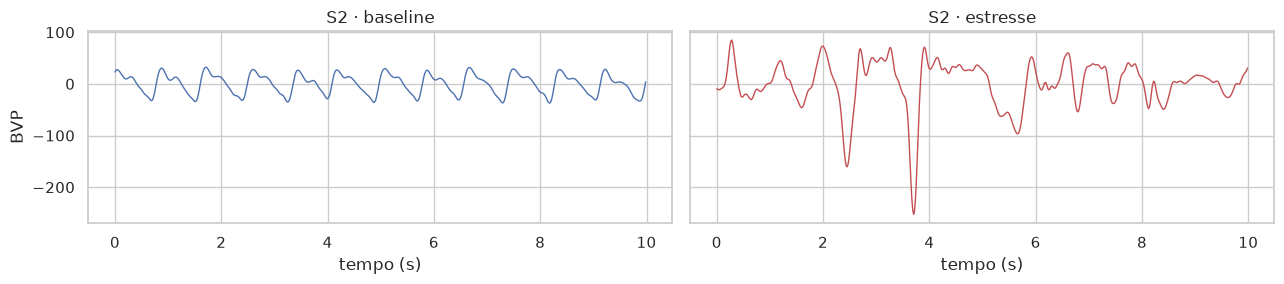

In [11]:
bvp = s2["BVP"]
fig, axes = plt.subplots(1, 2, figsize=(13, 3), sharey=True)
for ax, (lab, nome) in zip(axes, [(1, "baseline"), (2, "estresse")]):
    trecho = bvp[bvp.label == lab]
    t0 = trecho.t.iloc[len(trecho) // 2]               # meio da condição
    janela = trecho[(trecho.t >= t0) & (trecho.t < t0 + 10)]
    ax.plot(janela.t - t0, janela.bvp, color=COND_COLORS[nome], lw=1)
    ax.set_title(f"S2 · {nome}")
    ax.set_xlabel("tempo (s)")
axes[0].set_ylabel("BVP")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_bvp_zoom_S2.png", dpi=150)
plt.show()

## 5. As condições se diferenciam em todos os participantes?

Para cada participante e cada condição, calculamos a FC mediana, a EDA média, a temperatura média e o movimento médio. Como cada pessoa tem um nível de base diferente (a EDA média no baseline, por exemplo, vai de 0,13 µS no S4 a 5,11 µS no S13, uma diferença de quase 40 vezes), comparamos **a diferença em relação ao baseline da própria pessoa**.

In [12]:
linhas = []
for s in SUBJECTS:
    d = load_wrist(s)
    fc_bruta = fc_do_bvp(d["BVP"])
    fc = fc_bruta[fc_bruta.valido]
    for lab, cond in LABELS.items():
        linhas.append({
            "subject": s, "condicao": cond,
            "FC (bpm)": fc.loc[fc.label == lab, "fc"].median(),
            "EDA (µS)": d["EDA"].loc[d["EDA"].label == lab, "eda"].mean(),
            "TEMP (°C)": d["TEMP"].loc[d["TEMP"].label == lab, "temp"].mean(),
            "ACC |a| (g)": d["ACC"].loc[d["ACC"].label == lab, "mag"].mean(),
            "ruido FC (%)": 100 * (~fc_bruta.loc[fc_bruta.label == lab, "valido"]).mean(),
        })
por_cond = pd.DataFrame(linhas)
sinais = ["FC (bpm)", "EDA (µS)", "TEMP (°C)", "ACC |a| (g)"]

por_cond.groupby("condicao")[sinais + ["ruido FC (%)"]].mean().loc[list(LABELS.values())]

,FC (bpm),EDA (µS),TEMP (°C),ACC |a| (g),ruido FC (%)
condicao,,,,,
baseline,71.90,1.33,33.35,0.99,2.98
estresse,84.46,3.44,32.65,1.00,6.42
diversao,71.36,1.36,32.58,0.99,7.95
meditacao,69.14,1.39,32.01,0.99,7.20


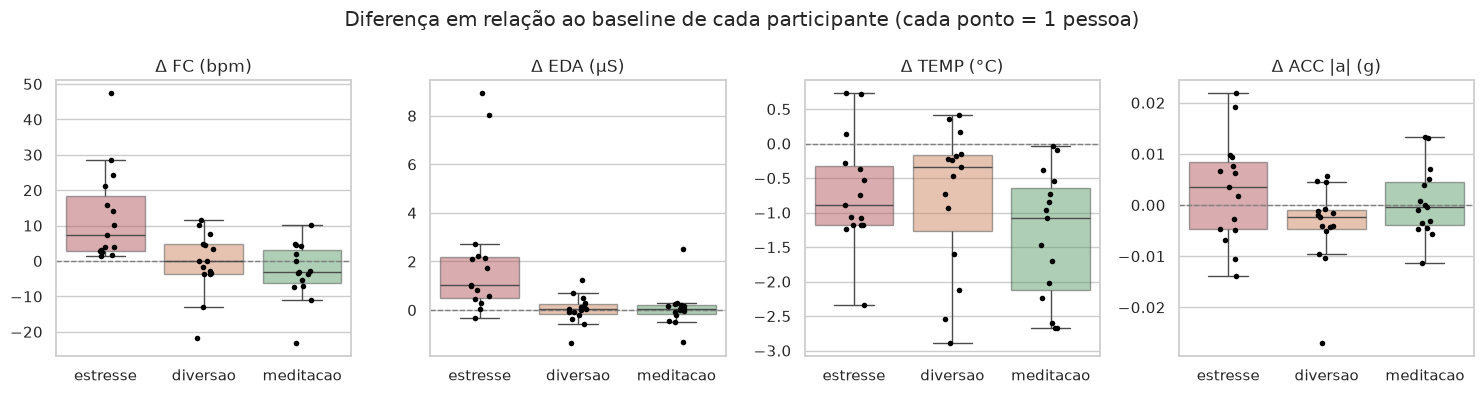

In [13]:
base = por_cond[por_cond.condicao == "baseline"].set_index("subject")[sinais]
outras = por_cond[por_cond.condicao != "baseline"]
delta = outras[["subject", "condicao"]].copy()
delta[sinais] = outras[sinais].to_numpy() - base.loc[outras.subject, sinais].to_numpy()

fig, axes = plt.subplots(1, 4, figsize=(15, 4))
ordem = ["estresse", "diversao", "meditacao"]
for ax, sinal in zip(axes, sinais):
    sns.boxplot(data=delta, x="condicao", y=sinal, order=ordem, hue="condicao",
                palette=COND_COLORS, ax=ax, fliersize=0, boxprops={"alpha": .5})
    sns.stripplot(data=delta, x="condicao", y=sinal, order=ordem, color="black", size=4, ax=ax)
    ax.axhline(0, color="grey", ls="--", lw=1)
    ax.set_title(f"Δ {sinal}")
    ax.set_xlabel(""); ax.set_ylabel("")
fig.suptitle("Diferença em relação ao baseline de cada participante (cada ponto = 1 pessoa)")
fig.tight_layout()
fig.savefig(FIG_DIR / "01_delta_baseline.png", dpi=150)
plt.show()

In [14]:
est = delta[delta.condicao == "estresse"].set_index("subject")[sinais]
pd.DataFrame({
    "Δ médio no estresse": est.mean(),
    "participantes com aumento": (est > 0).sum().astype(str) + f" de {len(est)}",
})

,Δ médio no estresse,participantes com aumento
FC (bpm),1.26e+01,15 de 15
EDA (µS),2.11e+00,14 de 15
TEMP (°C),-6.99e-01,3 de 15
ACC |a| (g),2.83e-03,9 de 15


## 6. Janelas de 60 s e equilíbrio das classes

Seguindo Schmidt et al. (2018), a tarefa binária é **estresse vs. não estresse**, em que não estresse = baseline + diversão. A meditação fica de fora da tarefa binária, como no artigo. Contamos quantas janelas de 60 s caberiam em cada condição sem misturar rótulos, com e sem sobreposição de 50%.

In [15]:
JANELA = 60
def n_janelas(dur_s: float, passo: float) -> int:
    return int(max(0, (dur_s - JANELA) // passo + 1))

linhas = []
for s in SUBJECTS:
    seg = segmentos(load_wrist(s)["TEMP"], WRIST_FS["TEMP"])
    for passo in (60, 30):
        for _, r in seg[seg.label.isin([1, 2, 3])].iterrows():
            linhas.append({"subject": s, "passo_s": passo,
                           "classe": "estresse" if r.label == 2 else "nao_estresse",
                           "janelas": n_janelas(r.fim_s - r.ini_s, passo)})
jan = (pd.DataFrame(linhas)
       .pivot_table(index="passo_s", columns="classe", values="janelas", aggfunc="sum"))
jan["total"] = jan.sum(axis=1)
jan["% estresse"] = 100 * jan["estresse"] / jan["total"]
jan.index = jan.index.map({60: "sem sobreposição (passo 60 s)", 30: "50% de sobreposição (passo 30 s)"})
jan

classe,estresse,nao_estresse,total,% estresse
passo_s,,,,
50% de sobreposição (passo 30 s),311,731,1042,29.85
sem sobreposição (passo 60 s),160,375,535,29.91


Para comparação: em Schmidt et al. (2018), o classificador que sempre responde "não estresse" já acerta 69,94% (F1 macro de 41,15%). Por isso vamos reportar **F1 macro e acurácia balanceada**, e não só a acurácia.

## 7. Sinais por custo de sensor (plano C)

O experimento central compara três conjuntos de indicadores, de acordo com o hardware necessário para medi-los:

| Conjunto | Indicadores | Sensor na Empatica E4 | Equivalente de baixo custo (ESP32) |
|---|---|---|---|
| **Baixo custo** | FC (média/mediana na janela), temperatura, movimento | PPG (BVP), termômetro, acelerômetro | Sensor óptico de pulso (ex.: MAX30102), sensor de temperatura de pele, acelerômetro (ex.: MPU-6050) |
| **Baixo custo + EDA** | o anterior + nível e picos de EDA | eletrodos de EDA | Sensor GSR (condutância da pele) |
| **Completo** | o anterior + HRV (RMSSD, pNN50, LF/HF) | PPG de boa qualidade | A HRV exige detectar cada batimento com precisão, o que um sensor óptico barato faz mal em movimento |

A comparação é **simulada**: os três conjuntos usam sinais da própria E4. Sensores baratos reais são mais ruidosos (MONTEIRO, 2022), então o resultado é o melhor cenário possível para o hardware barato.

## 8. Conclusões e decisões para o pré-processamento

**O que os dados mostram**

1. **A FC é o sinal mais consistente.** Ela sobe no estresse em **15 de 15** participantes, em média +12,6 bpm em relação ao baseline. Na diversão e na meditação não há mudança sistemática. É também o sinal mais fácil de medir com um sensor barato, o que é uma boa notícia para o experimento central (plano C).
2. **A EDA também sobe no estresse, em 14 de 15 participantes (+2,1 µS em média)**, mas o tamanho da subida varia muito: dois participantes sobem mais de 8 µS. No S2, a EDA continua alta alguns minutos depois que o estresse termina. Por isso, as janelas logo após a transição podem estar "contaminadas".
3. **A temperatura não é um marcador específico de estresse.** Ela cai no estresse em 12 de 15 participantes, mas também cai na diversão e na meditação. Ela acompanha o tempo de sessão e a temperatura da sala, e os participantes S8 e S16 relataram frio na sala do estresse. O risco é o modelo aprender "fim da sessão" em vez de "estresse".
4. **O movimento quase não muda entre as condições** (Δ de cerca de 0,003 g), porque no WESAD as pessoas ficam paradas, sentadas ou em pé. Na pulseira escolar, o acelerômetro vai servir mais para descartar janelas com artefato de movimento e para dar contexto (por exemplo, estereotipias motoras) do que como marcador de estresse.
5. **A FC do pulso é ruidosa.** De 3% a 8% dos batimentos ficam fora de 40 a 180 bpm, e o ruído é maior fora do baseline. A curva de FC do S2 oscila bastante mesmo em médias de 10 s.
6. **O conjunto é pequeno e desbalanceado.** Com janelas de 60 s há 535 janelas sem sobreposição (30% de estresse) ou 1.042 com 50% de sobreposição. Um classificador que sempre diz "não estresse" acerta cerca de 70%, como em Schmidt et al. (2018).
7. **As anotações dos participantes ajudam a explicar casos difíceis.** S6 e S15 relataram que não ficaram realmente estressados no TSST. S8 já chegou estressado. Se esses participantes tiverem desempenho ruim na validação LOSO, isso tem explicação.

**Decisões para o dia 7 (pré-processamento)**

| Decisão | Por quê |
|---|---|
| Janelas de 60 s com passo de 30 s, só com rótulo puro (sem misturar condições) | Dobra o número de exemplos. Com validação LOSO, a sobreposição não vaza informação entre treino e teste |
| Tarefa binária: estresse vs. (baseline + diversão); meditação fica de fora | Mesma tarefa de Schmidt et al. (2018), para poder comparar |
| FC: mediana dos intervalos válidos na janela, descartando de 40 a 180 bpm; janela inválida se mais de 20% dos batimentos forem ruído | Item 5 |
| **Normalizar cada indicador por participante** (z-score em relação ao baseline da própria pessoa) | Itens 1 e 2: o nível de base varia muito entre as pessoas. Na escola, isso equivale a uma calibração de alguns minutos de repouso no início do dia |
| EDA: separar nível tônico e respostas fásicas (picos) | Item 2: a subida e o número de picos dizem mais que o valor absoluto |
| TEMP: usar a inclinação na janela, não o valor absoluto, e comparar o modelo com e sem TEMP | Item 3: o valor absoluto depende do tempo de sessão e da sala |
| ACC: magnitude média e desvio padrão, também usados para marcar janelas com muito movimento | Item 4 |
| Modelos simples (LR, LDA, RF) antes do XGBoost | Item 6: poucos exemplos, 15 pessoas |

**Próximo passo:** no pré-processamento, marcar cada indicador com o conjunto de sensores de que depende (seção 7), para o experimento central poder treinar os três modelos a partir do mesmo arquivo de indicadores.